# Stage 7 — XAI faithfulness & sanity metrics (literature-comparable)

Stages 4–6 asked *"is the region Grad-CAM points to a real acoustic marker?"* (statistical,
causal, out-of-sample, signal-domain). This notebook asks a different question: *"is Grad-CAM
itself, as an explanation method, trustworthy here?"* — using the same metrics the saliency-map
literature uses to evaluate explanation methods in general, so the numbers below are
**comparable to other Grad-CAM / XAI papers**, not just internally to this project.

Three metric families, each from a specific, citable source:

1. **Deletion / Insertion AUC** (Petsiuk, Das & Saenko, *RISE*, BMVC 2018). Rank every
   time-frequency cell by Grad-CAM importance. Deletion: progressively replace the
   most-important cells with a neutral baseline and track P(MI) as a function of the fraction
   removed — AUC of that curve (**lower is better**: a faithful explanation should collapse P(MI)
   quickly). Insertion is the mirror image, starting from an all-baseline input and revealing
   important cells (**higher is better**). Both come with a random-order control curve.
2. **Average Drop % / Average Increase %** (Chattopadhay et al., *Grad-CAM++*, WACV 2018). Keep
   only the top-K% most important cells, re-run the model, and measure how much confidence
   drops (lower is better) or, in some recordings, actually *increases* despite seeing far less
   input (a sign the kept region was sufficient on its own).
3. **Cascading-randomization sanity check** (Adebayo et al., *Sanity Checks for Saliency Maps*,
   NeurIPS 2018). Progressively re-randomize the trained model's weights from the output layer
   back toward the input, recomputing Grad-CAM after each step, and measure how much the
   heatmap changes vs. the original. Many published saliency methods **fail** this test — if
   Grad-CAM's explanations degrade sharply here (as they should), that is a genuinely citable,
   positive claim about explanation validity, independent of what the markers themselves show.

This notebook reuses Stage 3's trained fold checkpoints and feature-extraction code exactly —
no retraining. It needs a GPU (or patience on CPU) and the raw `.wav` files, same as Stage 3.
Everything is saved to `artifacts/07_faithfulness_metrics/`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ---- Setup ----------------------------------------------------------------
import sys
import json
import copy
import datetime
import pathlib

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

package_path = "/content/drive/MyDrive/Research 2026/mi_marker_pipeline"
if package_path not in sys.path:
    sys.path.insert(0, package_path)

from pipeline_common import config
from pipeline_common.audio import load_and_resample, pad_or_trim
from pipeline_common.features import calculate_features, n_freq_bins
from pipeline_common.models import make_model
from pipeline_common.explain import GradCAM
from pipeline_common.faithfulness import (
    deletion_insertion_curves, top_k_mask, average_drop_increase,
    rank_correlation, summarize_randomization_sweep,
)

import random
random.seed(config.SEED); np.random.seed(config.SEED); torch.manual_seed(config.SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SPLIT_DIR = config.ARTIFACTS_DIR / "01_split"
TRAIN_DIR = config.ARTIFACTS_DIR / "03_train_explain"
MODELS_DIR = TRAIN_DIR / "models"
STAGE_DIR = config.ARTIFACTS_DIR / "07_faithfulness_metrics"
STAGE_DIR.mkdir(parents=True, exist_ok=True)

N_FREQ_BINS = n_freq_bins()
print("Saving this stage's output to:", STAGE_DIR)

Using device: cuda
Saving this stage's output to: /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/07_faithfulness_metrics


## 1. Load Stage 3's fold checkpoints + out-of-fold predictions

No retraining — this notebook only ever loads the exact weights Stage 3 already produced, so
every metric below describes the same model that Stages 3–6 evaluated.

In [3]:
oof_df = pd.read_csv(TRAIN_DIR / "out_of_fold_predictions.csv")

fold_models = {}
for fold_idx in range(config.N_FOLDS):
    model = make_model(N_FREQ_BINS, DEVICE)
    state_dict = torch.load(MODELS_DIR / f"fold_{fold_idx}.pt", map_location=DEVICE)
    model.load_state_dict(state_dict)
    model.eval()
    fold_models[fold_idx] = model

print(f"Loaded {len(fold_models)} fold checkpoints; {len(oof_df)} out-of-fold recordings available")

Loaded 5 fold checkpoints; 2688 out-of-fold recordings available


## 2. Wire a real forward pass into `faithfulness.py`'s model-agnostic functions

`faithfulness.py` has no torch dependency of its own — every function that needs the model
takes a plain `forward_fn(batch: np.ndarray[N, freq, time]) -> np.ndarray[N, n_classes]`
(already softmaxed). This cell is the only place torch touches those functions.

**Resolution note:** Grad-CAM is read from `model.conv2`'s activations, which sit *after*
`conv1`'s 2x2 max-pool — so the raw heatmap is exactly half the input spectrogram's resolution
in both frequency and time (e.g. 20x124 vs. the input's 40x248). Every function below that
uses a cam together with the raw feature (`deletion_insertion_curves`, `top_k_mask`) requires
them to be the *same* shape and raises a clear error otherwise — so `get_cam_and_resize` here
is the one place that resize happens, applied consistently everywhere a cam is used.

In [4]:
import torch.nn.functional as TF

def make_forward_fn(model):
    @torch.no_grad()
    def forward_fn(batch_np):
        batch = torch.from_numpy(batch_np).float().to(DEVICE)
        logits = model(batch)
        return torch.softmax(logits, dim=1).cpu().numpy()
    return forward_fn

def get_cam_and_resize(model, x, class_idx, target_shape):
    """Computes Grad-CAM (at model.conv2's native, pooled resolution) and immediately
    upsamples it to `target_shape` (the raw input feature's resolution) via bilinear
    interpolation -- the standard choice in the saliency-map literature for this exact
    situation. Returns (cam_resized, probs). Do this once per recording, right after computing
    the cam, and use the resized version everywhere downstream -- never the raw-resolution cam.
    """
    cam_engine = GradCAM(model, model.conv2)
    cam, probs = cam_engine(x, class_idx=class_idx)
    if cam.shape != target_shape:
        cam_t = torch.from_numpy(cam).float().unsqueeze(0).unsqueeze(0)
        cam_t = TF.interpolate(cam_t, size=target_shape, mode="bilinear", align_corners=False)
        cam = cam_t.squeeze().numpy()
    return cam, probs

## 3. Deletion / Insertion AUC + Average Drop% / Increase%

Computed on a stratified subsample of the out-of-fold set (`N_SAMPLE_RECORDINGS`, default 200)
— standard practice for these metrics, since each recording needs ~`2 x 2 x (n_steps+1)`
forward passes (deletion+insertion, cam+random). Raise `N_SAMPLE_RECORDINGS` toward `len(oof_df)`
if your GPU budget allows the full out-of-fold set.

In [5]:
N_SAMPLE_RECORDINGS = 200
N_STEPS = 20                 # deletion/insertion curve resolution
TOP_K_FRACTION = 0.25        # for average drop/increase: keep the top 25% of cells
BASELINE_VALUE = 0.0         # features are per-recording z-normalised, so 0 = "uninformative"

sample_df = (
    oof_df.groupby("class_name", group_keys=False)
    .apply(lambda g: g.sample(min(len(g), N_SAMPLE_RECORDINGS // 2), random_state=config.SEED))
    .reset_index(drop=True)
)
print(f"Faithfulness metrics computed on {len(sample_df)} recordings "
      f"({sample_df['class_name'].value_counts().to_dict()})")

Faithfulness metrics computed on 200 recordings ({'Myocardial': 100, 'Normal': 100})


/tmp/ipykernel_6864/3719412810.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), N_SAMPLE_RECORDINGS // 2), random_state=config.SEED))


In [6]:
rng = np.random.default_rng(config.SEED)
faithfulness_rows = []

for _, row in sample_df.iterrows():
    model = fold_models[row["fold_index"]]   # the model that never saw this patient in training
    forward_fn = make_forward_fn(model)

    signal = pad_or_trim(load_and_resample(row["filepath"], config.SAMPLE_RATE),
                         config.SAMPLE_RATE, config.CLIP_SECONDS)
    feature = calculate_features(signal)

    x = torch.from_numpy(feature).float().unsqueeze(0).to(DEVICE)
    cam, probs_full = get_cam_and_resize(model, x, config.GRADCAM_TARGET_CLASS, feature.shape)
    p_full = float(probs_full[config.GRADCAM_TARGET_CLASS])

    # -- deletion / insertion (cam is already resized to feature's resolution) --
    di = deletion_insertion_curves(forward_fn, feature, cam, target_class=config.GRADCAM_TARGET_CLASS,
                                   n_steps=N_STEPS, baseline_value=BASELINE_VALUE, rng=rng)

    # -- average drop / increase --
    mask = top_k_mask(cam, top_fraction=TOP_K_FRACTION, feature_shape=feature.shape)
    masked_feature = np.where(mask, feature, BASELINE_VALUE).astype(np.float32)
    p_masked = float(forward_fn(masked_feature[None])[0, config.GRADCAM_TARGET_CLASS])

    faithfulness_rows.append({
        "filepath": row["filepath"], "patient_id": row["patient_id"],
        "class_name": row["class_name"], "fold_index": row["fold_index"],
        "p_full": p_full, "p_masked_top25": p_masked,
        "deletion_auc_cam": di["deletion_cam_auc"], "deletion_auc_random": di["deletion_random_auc"],
        "insertion_auc_cam": di["insertion_cam_auc"], "insertion_auc_random": di["insertion_random_auc"],
    })

faithfulness_df = pd.DataFrame(faithfulness_rows)
faithfulness_df.to_csv(STAGE_DIR / "deletion_insertion_per_recording.csv", index=False)
faithfulness_df.head()

,filepath,patient_id,class_name,fold_index,p_full,p_masked_top25,deletion_auc_cam,deletion_auc_random,insertion_auc_cam,insertion_auc_random
0,/content/drive/MyDrive/Research 2026/Segmented...,P0001,Myocardial,0,0.985184,0.081112,0.379797,0.420913,0.598168,0.509124
1,/content/drive/MyDrive/Research 2026/Segmented...,P0064,Myocardial,0,0.962289,0.018384,0.227408,0.363272,0.402562,0.379489
2,/content/drive/MyDrive/Research 2026/Segmented...,P0050,Myocardial,3,0.967678,0.986382,0.624335,0.948329,0.975790,0.966366
3,/content/drive/MyDrive/Research 2026/Segmented...,P0049,Myocardial,0,0.986093,0.465138,0.592080,0.490902,0.724849,0.517725
4,/content/drive/MyDrive/Research 2026/Segmented...,P0049,Myocardial,0,0.984845,0.614494,0.785484,0.629203,0.755114,0.661405


In [7]:
drop_pct, increase_pct = average_drop_increase(faithfulness_df["p_full"], faithfulness_df["p_masked_top25"])

faithfulness_summary = {
    "n_recordings": int(len(faithfulness_df)),
    "deletion_auc_cam_mean": float(faithfulness_df["deletion_auc_cam"].mean()),
    "deletion_auc_random_mean": float(faithfulness_df["deletion_auc_random"].mean()),
    "insertion_auc_cam_mean": float(faithfulness_df["insertion_auc_cam"].mean()),
    "insertion_auc_random_mean": float(faithfulness_df["insertion_auc_random"].mean()),
    "average_drop_pct": drop_pct,
    "average_increase_pct": increase_pct,
    "top_k_fraction": TOP_K_FRACTION,
    "n_steps": N_STEPS,
    "baseline_value": BASELINE_VALUE,
}
print(json.dumps(faithfulness_summary, indent=2))

# a quick paired check: cam should beat random on both curves for the *average* recording,
# not just in aggregate -- report the fraction of recordings where that holds, since a metric
# that only wins "on average" (driven by outliers) is weaker evidence than one that wins
# consistently.
deletion_wins = (faithfulness_df["deletion_auc_cam"] < faithfulness_df["deletion_auc_random"]).mean()
insertion_wins = (faithfulness_df["insertion_auc_cam"] > faithfulness_df["insertion_auc_random"]).mean()
print(f"\ncam beats random on deletion in {deletion_wins:.1%} of recordings")
print(f"cam beats random on insertion in {insertion_wins:.1%} of recordings")

{
  "n_recordings": 200,
  "deletion_auc_cam_mean": 0.26363679629971737,
  "deletion_auc_random_mean": 0.40878491263382605,
  "insertion_auc_cam_mean": 0.41938616377429566,
  "insertion_auc_random_mean": 0.414865819065366,
  "average_drop_pct": 50.392629996530715,
  "average_increase_pct": 28.999999999999996,
  "top_k_fraction": 0.25,
  "n_steps": 20,
  "baseline_value": 0.0
}

cam beats random on deletion in 83.5% of recordings
cam beats random on insertion in 46.0% of recordings


## 4. Example deletion/insertion curves (a few recordings)

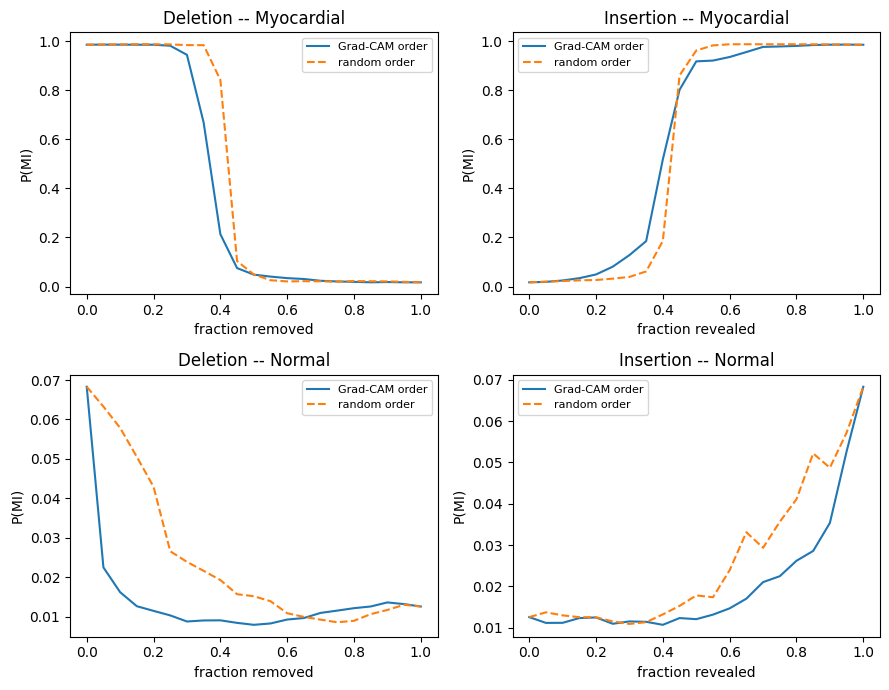

In [8]:
example_rows = sample_df.groupby("class_name").head(1)
fig, axes = plt.subplots(len(example_rows), 2, figsize=(9, 3.5 * len(example_rows)))
if len(example_rows) == 1:
    axes = axes[None, :]

for i, (_, row) in enumerate(example_rows.iterrows()):
    model = fold_models[row["fold_index"]]
    forward_fn = make_forward_fn(model)
    signal = pad_or_trim(load_and_resample(row["filepath"], config.SAMPLE_RATE),
                         config.SAMPLE_RATE, config.CLIP_SECONDS)
    feature = calculate_features(signal)
    x = torch.from_numpy(feature).float().unsqueeze(0).to(DEVICE)
    cam, _ = get_cam_and_resize(model, x, config.GRADCAM_TARGET_CLASS, feature.shape)
    di = deletion_insertion_curves(forward_fn, feature, cam, target_class=config.GRADCAM_TARGET_CLASS,
                                   n_steps=N_STEPS, baseline_value=BASELINE_VALUE,
                                   rng=np.random.default_rng(0))

    axes[i, 0].plot(di["fractions"], di["deletion_cam"], label="Grad-CAM order")
    axes[i, 0].plot(di["fractions"], di["deletion_random"], label="random order", linestyle="--")
    axes[i, 0].set_title(f"Deletion -- {row['class_name']}"); axes[i, 0].set_xlabel("fraction removed")
    axes[i, 0].set_ylabel("P(MI)"); axes[i, 0].legend(fontsize=8)

    axes[i, 1].plot(di["fractions"], di["insertion_cam"], label="Grad-CAM order")
    axes[i, 1].plot(di["fractions"], di["insertion_random"], label="random order", linestyle="--")
    axes[i, 1].set_title(f"Insertion -- {row['class_name']}"); axes[i, 1].set_xlabel("fraction revealed")
    axes[i, 1].set_ylabel("P(MI)"); axes[i, 1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(STAGE_DIR / "deletion_insertion_example_curves.png", dpi=150)
plt.show()

## 5. Cascading-randomization sanity check (Adebayo et al. 2018)

Cascade order (output → input, cumulative): `head` → `rnn` → `conv2` → `conv1`. At each step,
every module from the previous steps *and* the current one has been re-initialised (fresh
random weights via each layer's own `reset_parameters()` — the standard PyTorch API every
`Conv2d` / `Linear` / `BatchNorm2d` / `GRU` module defines), so randomization accumulates rather
than being undone between steps. Run on a smaller sample (`N_SANITY_RECORDINGS`) since it needs
a fresh Grad-CAM per recording per cascade step.

In [9]:
N_SANITY_RECORDINGS = 24
CASCADE_ORDER = ["head", "rnn", "conv2", "conv1"]   # output -> input

def randomize_module_(module):
    """In-place re-init of every submodule that defines reset_parameters (Conv2d, Linear,
    BatchNorm2d, GRU all do) -- standard PyTorch API, not a hand-rolled re-init scheme."""
    for m in module.modules():
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()

sanity_sample = (
    oof_df.groupby("class_name", group_keys=False)
    .apply(lambda g: g.sample(min(len(g), N_SANITY_RECORDINGS // 2), random_state=config.SEED))
    .reset_index(drop=True)
)
print(f"Sanity check computed on {len(sanity_sample)} recordings")

Sanity check computed on 24 recordings


/tmp/ipykernel_6864/2101240462.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), N_SANITY_RECORDINGS // 2), random_state=config.SEED))


In [10]:
sanity_rows = []

for _, row in sanity_sample.iterrows():
    base_model = fold_models[row["fold_index"]]
    signal = pad_or_trim(load_and_resample(row["filepath"], config.SAMPLE_RATE),
                         config.SAMPLE_RATE, config.CLIP_SECONDS)
    feature = calculate_features(signal)
    x = torch.from_numpy(feature).float().unsqueeze(0).to(DEVICE)

    # step 0: the original, fully-trained model (similarity to itself = 1.0 by construction)
    cam_engine = GradCAM(base_model, base_model.conv2)
    original_cam, _ = cam_engine(x, class_idx=config.GRADCAM_TARGET_CLASS)
    sanity_rows.append({"filepath": row["filepath"], "cascade_step": 0,
                        "layer_randomized": "none (original)", "similarity": 1.0})

    cascaded_model = copy.deepcopy(base_model)
    for step, layer_name in enumerate(CASCADE_ORDER, start=1):
        randomize_module_(getattr(cascaded_model, layer_name))
        cascaded_model.eval()
        cam_engine_c = GradCAM(cascaded_model, cascaded_model.conv2)
        cam_c, _ = cam_engine_c(x, class_idx=config.GRADCAM_TARGET_CLASS)
        sim = rank_correlation(original_cam, cam_c)
        sanity_rows.append({"filepath": row["filepath"], "cascade_step": step,
                            "layer_randomized": layer_name, "similarity": sim})

sanity_df = pd.DataFrame(sanity_rows)
sanity_df.to_csv(STAGE_DIR / "sanity_check_per_recording.csv", index=False)

sanity_summary = pd.DataFrame(summarize_randomization_sweep(sanity_rows))
sanity_summary.to_csv(STAGE_DIR / "sanity_check_summary.csv", index=False)
sanity_summary

,cascade_step,layer_randomized,mean_similarity,std_similarity,n
0,0,none (original),1.000000,0.000000,24
1,1,head,0.016789,0.476917,24
2,2,rnn,0.005863,0.286967,24
3,3,conv2,-0.038933,0.269619,24
4,4,conv1,0.017424,0.220136,24


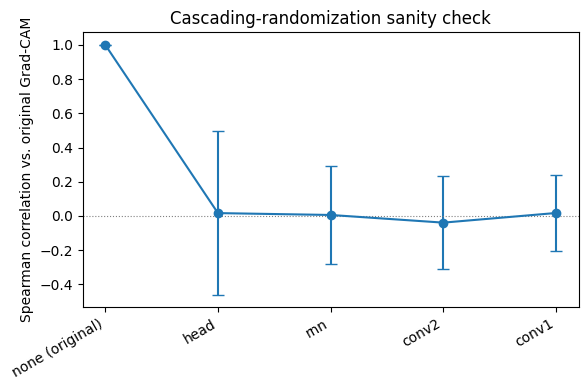

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(sanity_summary["cascade_step"], sanity_summary["mean_similarity"],
           yerr=sanity_summary["std_similarity"], marker="o", capsize=4)
ax.set_xticks(sanity_summary["cascade_step"])
ax.set_xticklabels(sanity_summary["layer_randomized"], rotation=30, ha="right")
ax.set_ylabel("Spearman correlation vs. original Grad-CAM")
ax.set_title("Cascading-randomization sanity check")
ax.axhline(0, color="grey", linewidth=0.8, linestyle=":")
plt.tight_layout()
plt.savefig(STAGE_DIR / "sanity_check_plot.png", dpi=150)
plt.show()

## 6. Save config + short summary

In [12]:
config_used = {
    "stage": "07_faithfulness_metrics",
    "generated": datetime.datetime.now().isoformat(),
    "n_sample_recordings_faithfulness": int(len(faithfulness_df)),
    "n_sample_recordings_sanity": int(len(sanity_sample)),
    "n_steps": N_STEPS, "top_k_fraction": TOP_K_FRACTION, "baseline_value": BASELINE_VALUE,
    "cascade_order": CASCADE_ORDER, "seed": config.SEED,
    "faithfulness_summary": faithfulness_summary,
}
with open(STAGE_DIR / "config_used.json", "w") as f:
    json.dump(config_used, f, indent=2)

lines = ["# Stage 7 -- XAI Faithfulness & Sanity Metrics\n",
        f"Generated: {config_used['generated']}\n\n",
        "Standard, literature-comparable metrics for the Grad-CAM explanations underlying "
        "Stages 3-4, computed on the trained (not retrained) fold models.\n\n",
        "## Deletion / Insertion AUC (Petsiuk et al. 2018)\n\n",
        f"- Deletion AUC -- Grad-CAM order: {faithfulness_summary['deletion_auc_cam_mean']:.4f} "
        f"vs. random order: {faithfulness_summary['deletion_auc_random_mean']:.4f} "
        "(lower is better; Grad-CAM order should be lower)\n",
        f"- Insertion AUC -- Grad-CAM order: {faithfulness_summary['insertion_auc_cam_mean']:.4f} "
        f"vs. random order: {faithfulness_summary['insertion_auc_random_mean']:.4f} "
        "(higher is better; Grad-CAM order should be higher)\n",
        f"- Grad-CAM beat random on deletion in {deletion_wins:.1%} of sampled recordings, "
        f"on insertion in {insertion_wins:.1%}\n\n",
        "## Average Drop% / Increase% (Chattopadhay et al. 2018)\n\n",
        f"- Average Drop: {faithfulness_summary['average_drop_pct']:.2f}% "
        f"(keeping only the top {int(TOP_K_FRACTION*100)}% of cells by Grad-CAM importance)\n",
        f"- Average Increase: {faithfulness_summary['average_increase_pct']:.2f}% "
        "of recordings had HIGHER confidence with only that region shown\n\n",
        "## Cascading-randomization sanity check (Adebayo et al. 2018)\n\n"]
for _, r in sanity_summary.iterrows():
    lines.append(f"- Step {int(r['cascade_step'])} ({r['layer_randomized']}): "
                f"mean similarity to original = {r['mean_similarity']:.3f} "
                f"(std {r['std_similarity']:.3f}, n={int(r['n'])})\n")
lines.append("\nA meaningful explanation should show similarity dropping toward 0 (or negative) "
            "as more of the model is randomized; similarity staying high through full "
            "randomization would indicate Grad-CAM is behaving like a fixed, model-independent "
            "edge detector here.\n")

with open(STAGE_DIR / "final_report_stage7.md", "w") as f:
    f.writelines(lines)

print("".join(lines))

# Stage 7 -- XAI Faithfulness & Sanity Metrics
Generated: 2026-09-20T00:11:34.088753

Standard, literature-comparable metrics for the Grad-CAM explanations underlying Stages 3-4, computed on the trained (not retrained) fold models.

## Deletion / Insertion AUC (Petsiuk et al. 2018)

- Deletion AUC -- Grad-CAM order: 0.2636 vs. random order: 0.4088 (lower is better; Grad-CAM order should be lower)
- Insertion AUC -- Grad-CAM order: 0.4194 vs. random order: 0.4149 (higher is better; Grad-CAM order should be higher)
- Grad-CAM beat random on deletion in 83.5% of sampled recordings, on insertion in 46.0%

## Average Drop% / Increase% (Chattopadhay et al. 2018)

- Average Drop: 50.39% (keeping only the top 25% of cells by Grad-CAM importance)
- Average Increase: 29.00% of recordings had HIGHER confidence with only that region shown

## Cascading-randomization sanity check (Adebayo et al. 2018)

- Step 0 (none (original)): mean similarity to original = 1.000 (std 0.000, n=24)
- Step 1 (head)